In [1]:
import numpy as np  
import matplotlib.pyplot as plt

# Used whenever a function is called without an explicit generator.
_default_rng = np.random.default_rng()

## Testing setting up

In [2]:
def initialize_lattice(n, seed=None, startcold=True, rng=None):
    if rng is not None and seed is not None:
        raise ValueError("Pass either seed or rng, not both.")
    if rng is None:
        rng = np.random.default_rng(seed)
    if startcold:
        lattice = np.ones((n, n), dtype=np.int8)
    else:
        lattice = rng.integers(0, 2, size=(n, n), dtype=np.int8)
        lattice[lattice == 0] = -1
    return lattice

In [3]:
def random_spin(lattice, rng=None):
    if rng is None:
        rng = _default_rng
    n = lattice.shape[0]
    i, j = rng.integers(0, n, size=2)
    return i, j

In [4]:
def Hamiltonian(lattice, J=1):
    right_neighbours = np.roll(lattice, shift=-1, axis=1)
    bottom_neighbours = np.roll(lattice, shift=-1, axis=0)
    return -J * np.sum(lattice * (right_neighbours + bottom_neighbours))


In [5]:
def magnetization(lattice):
    return np.sum(lattice) / lattice.size

In [6]:
def metropolis_update(lattice, beta, rng=None, J=1):
    """Attempt one spin flip in place and return (delta_energy, delta_spin_sum)."""
    if rng is None:
        rng = _default_rng

    n = lattice.shape[0]
    i, j = random_spin(lattice, rng)
    spin = int(lattice[i, j])
    neighbour_sum = (
        lattice[(i + 1) % n, j]
        + lattice[(i - 1) % n, j]
        + lattice[i, (j + 1) % n]
        + lattice[i, (j - 1) % n]
    )
    delta_energy = 2 * J * spin * int(neighbour_sum)

    if delta_energy <= 0 or rng.random() < np.exp(-beta * delta_energy):
        lattice[i, j] = -spin
        return delta_energy, -2 * spin
    return 0, 0


def metropolis_step(lattice, beta, rng=None, J=1):
    """Backward-compatible one-step function used by the earlier cells."""
    metropolis_update(lattice, beta, rng=rng, J=J)
    return lattice, Hamiltonian(lattice, J=J), magnetization(lattice)

In [7]:
t=10000
H_dyn=np.zeros(t)
M=np.zeros(t)
lattice = initialize_lattice(100)
for i in range(t):
    lattice, H_dyn[i], M[i] = metropolis_step(lattice, beta=1.0)
    

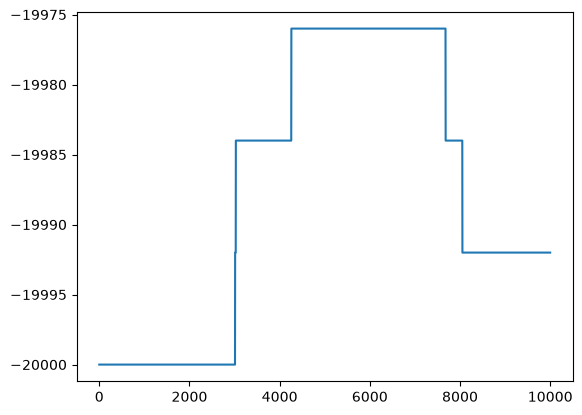

In [8]:
plt.plot(H_dyn)

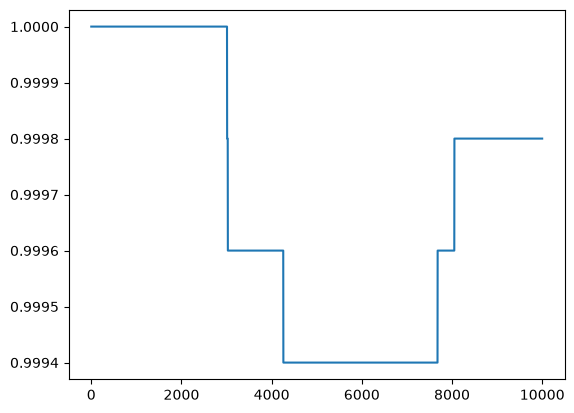

In [9]:
plt.plot(M)

I expreienced that altough I used the same seed, the equillibrium was reached in different timesteps in different runs, both in magnetization and in energy, sometimes around 2000 sometimes around 8000

## Getting it compatible with $m(0.5)=0.911319...$

In [29]:
t=200000
H_dyn=np.zeros(t)
M=np.zeros(t)
lattice = initialize_lattice(15)
for i in range(t):
    lattice, H_dyn[i], M[i] = metropolis_step(lattice, beta=0.5)
    

In [ ]:
M_eq=M from 

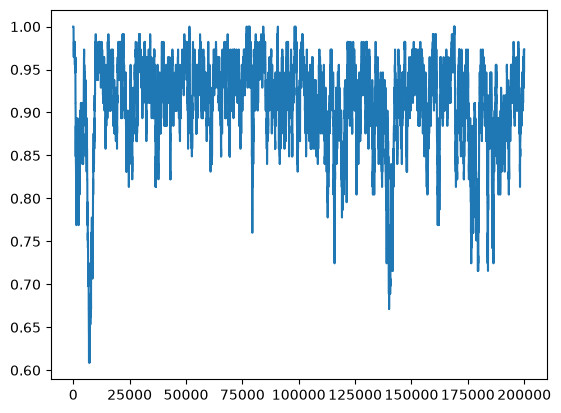

In [30]:
plt.plot(M)

In [22]:
print(np.mean(M[150000:]))
print(np.std(M[150000:]))
print(np.var(M[150000:]))

0.9161150222222222
0.04188238304340583
0.0017541340093945683


## Hot/cold ensemble relaxation

`run_relaxation_ensemble` runs the same number of cold and hot starts. Time is stored in Monte Carlo sweeps (attempted flips divided by the number of lattice sites). For `M`, absolute magnetization is used by default so that positive and negative ordered states do not cancel.

In [13]:
def run_trajectory(lattice_size, beta, n_steps, startcold, observable, rng,
                   J=1, measure_every=1, absolute_magnetization=True):
    """Run one trajectory and return its sampled observable."""
    if n_steps < 1 or measure_every < 1:
        raise ValueError("n_steps and measure_every must be positive integers.")

    observable = observable.upper()
    if observable not in {"H", "M"}:
        raise ValueError("observable must be 'H' or 'M'.")

    lattice = initialize_lattice(lattice_size, startcold=startcold, rng=rng)
    energy = float(Hamiltonian(lattice, J=J))
    spin_sum = int(np.sum(lattice))

    sample_steps = np.arange(0, n_steps + 1, measure_every, dtype=int)
    if sample_steps[-1] != n_steps:
        sample_steps = np.append(sample_steps, n_steps)
    values = np.empty(sample_steps.size, dtype=float)

    def current_value():
        if observable == "H":
            return energy
        value = spin_sum / lattice.size
        return abs(value) if absolute_magnetization else value

    values[0] = current_value()
    previous_step = 0
    for sample_index, target_step in enumerate(sample_steps[1:], start=1):
        for _ in range(target_step - previous_step):
            delta_energy, delta_spin_sum = metropolis_update(
                lattice, beta, rng=rng, J=J
            )
            energy += delta_energy
            spin_sum += delta_spin_sum
        values[sample_index] = current_value()
        previous_step = target_step

    time_sweeps = sample_steps / lattice.size
    return time_sweeps, values


def fit_relaxation_exponential(time, difference, fit_start=0, fit_stop=None,
                               fit_offset=False):
    """Fit D(t) = A exp(-t/tau) + C using only NumPy."""
    time = np.asarray(time, dtype=float)
    difference = np.asarray(difference, dtype=float)
    stop = len(time) if fit_stop is None else fit_stop
    t = time[fit_start:stop]
    y = difference[fit_start:stop]
    finite = np.isfinite(t) & np.isfinite(y)
    t, y = t[finite], y[finite]
    if t.size < 3 or t[-1] <= t[0]:
        raise ValueError("The fit window must contain at least three distinct samples.")

    # Shift the fit window to avoid an unnecessary exp(-large number).
    t_origin = t[0]
    shifted_t = t - t_origin
    positive_dt = np.diff(t)
    positive_dt = positive_dt[positive_dt > 0]
    dt = positive_dt.min()
    span = shifted_t[-1]
    low_tau = max(dt / 10, np.finfo(float).eps)
    high_tau = max(span * 100, low_tau * 10)

    best = None
    for _ in range(3):
        taus = np.geomspace(low_tau, high_tau, 300)
        for tau in taus:
            exponential = np.exp(-shifted_t / tau)
            if fit_offset:
                x_centered = exponential - exponential.mean()
                denominator = np.dot(x_centered, x_centered)
                amplitude = (np.dot(x_centered, y - y.mean()) / denominator
                             if denominator > 0 else 0.0)
                offset = y.mean() - amplitude * exponential.mean()
            else:
                amplitude = np.dot(exponential, y) / np.dot(exponential, exponential)
                offset = 0.0
            residual = y - (amplitude * exponential + offset)
            rss = np.dot(residual, residual)
            if best is None or rss < best[0]:
                best = (rss, tau, amplitude, offset)

        best_index = np.searchsorted(taus, best[1])
        lower_index = max(0, best_index - 2)
        upper_index = min(len(taus) - 1, best_index + 1)
        low_tau, high_tau = taus[lower_index], taus[upper_index]

    rss, tau, amplitude_at_origin, offset = best
    amplitude = amplitude_at_origin * np.exp(t_origin / tau)
    fitted_curve = amplitude * np.exp(-time / tau) + offset
    return {
        "amplitude": amplitude,
        "offset": offset,
        "tau": tau,
        "relaxation_time": tau,
        "time_to_1_percent": tau * np.log(100),
        "fitted_curve": fitted_curve,
        "rmse": np.sqrt(rss / t.size),
        "fit_start": fit_start,
        "fit_stop": stop,
        "fit_offset": fit_offset,
    }


def run_relaxation_ensemble(lattice_size, beta, n_runs, n_steps, observable="H",
                            J=1, seed=None, measure_every=1,
                            absolute_magnetization=True, fit_start=0,
                            fit_stop=None, fit_offset=False):
    """Run n_runs cold starts and n_runs hot starts and fit their difference."""
    if lattice_size < 2 or n_runs < 2:
        raise ValueError("lattice_size and n_runs must both be at least 2.")

    seed_sequences = np.random.SeedSequence(seed).spawn(2 * n_runs)
    cold_runs = []
    hot_runs = []
    time_sweeps = None

    for run_index in range(n_runs):
        cold_rng = np.random.default_rng(seed_sequences[run_index])
        hot_rng = np.random.default_rng(seed_sequences[n_runs + run_index])
        time_sweeps, cold_values = run_trajectory(
            lattice_size, beta, n_steps, True, observable, cold_rng,
            J=J, measure_every=measure_every,
            absolute_magnetization=absolute_magnetization
        )
        _, hot_values = run_trajectory(
            lattice_size, beta, n_steps, False, observable, hot_rng,
            J=J, measure_every=measure_every,
            absolute_magnetization=absolute_magnetization
        )
        cold_runs.append(cold_values)
        hot_runs.append(hot_values)

    cold_runs = np.asarray(cold_runs)
    hot_runs = np.asarray(hot_runs)
    cold_mean = cold_runs.mean(axis=0)
    hot_mean = hot_runs.mean(axis=0)
    cold_sem = cold_runs.std(axis=0, ddof=1) / np.sqrt(n_runs)
    hot_sem = hot_runs.std(axis=0, ddof=1) / np.sqrt(n_runs)
    difference = cold_mean - hot_mean
    difference_sem = np.sqrt(cold_sem**2 + hot_sem**2)
    fit = fit_relaxation_exponential(
        time_sweeps, difference, fit_start=fit_start, fit_stop=fit_stop,
        fit_offset=fit_offset
    )

    result = {
        "parameters": {
            "lattice_size": lattice_size, "beta": beta, "n_runs": n_runs,
            "n_steps": n_steps, "observable": observable.upper(), "J": J,
            "seed": seed, "measure_every": measure_every,
            "absolute_magnetization": absolute_magnetization,
        },
        "time": time_sweeps,
        "cold_runs": cold_runs,
        "hot_runs": hot_runs,
        "cold_mean": cold_mean,
        "hot_mean": hot_mean,
        "cold_sem": cold_sem,
        "hot_sem": hot_sem,
        "difference": difference,
        "difference_sem": difference_sem,
        "fit": fit,
    }
    return result


def plot_relaxation(result):
    """Plot the stored ensemble averages, difference, and exponential fit."""
    time = result["time"]
    label = result["parameters"]["observable"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(time, result["cold_mean"], label="cold average")
    axes[0].plot(time, result["hot_mean"], label="hot average")
    axes[0].set(xlabel="Monte Carlo sweeps", ylabel=label)
    axes[0].legend()

    axes[1].plot(time, result["difference"], label="cold - hot")
    axes[1].plot(time, result["fit"]["fitted_curve"], "--",
                 label=f"fit: tau = {result['fit']['tau']:.3g} sweeps")
    axes[1].set(xlabel="Monte Carlo sweeps", ylabel=f"difference in {label}")
    axes[1].legend()
    fig.tight_layout()
    return fig, axes

Relaxation time: 35.829 sweeps
Time to 1%: 164.998 sweeps


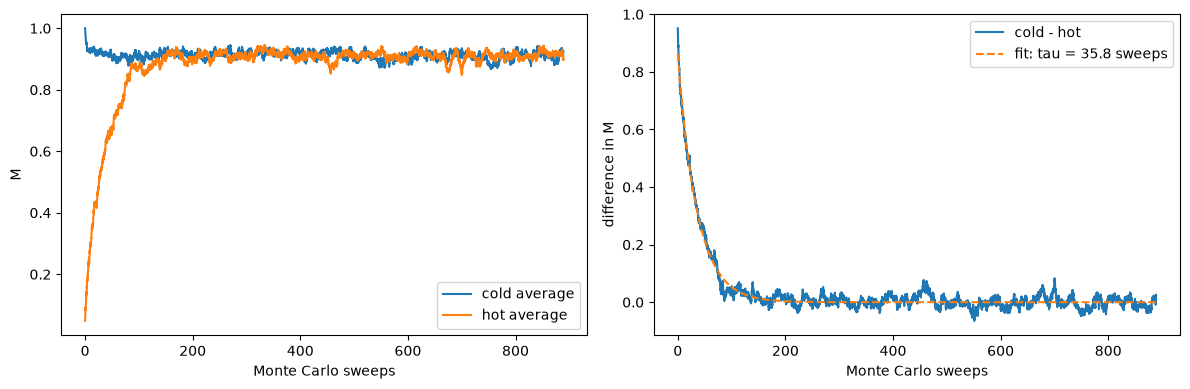

In [19]:
# Example: the complete result is retained in relaxation_M for later analysis.
relaxation_M = run_relaxation_ensemble(
    lattice_size=15,
    beta=0.5,
    n_runs=20,       # 10 cold runs and 10 hot runs
    n_steps=200000,  # attempted single-spin flips per run
    observable="M",
    measure_every=20,
    seed=42,
)

print(f"Relaxation time: {relaxation_M['fit']['tau']:.3f} sweeps")
print(f"Time to 1%: {relaxation_M['fit']['time_to_1_percent']:.3f} sweeps")
plot_relaxation(relaxation_M);

In [ ]:
def block_magnetization_statistics(magnetization_values, n_blocks):
    """Estimate the mean and its uncertainty using contiguous time blocks.

    The time series is divided into ``n_blocks`` contiguous blocks. The
    variance of the overall mean is estimated from the sample variance of
    the block means: Var(mean) = Var(block means) / n_blocks.
    """
    values = np.asarray(magnetization_values, dtype=float)

    if values.ndim != 1:
        raise ValueError("magnetization_values must be a one-dimensional array.")
    if not isinstance(n_blocks, (int, np.integer)) or isinstance(n_blocks, bool):
        raise TypeError("n_blocks must be an integer.")
    if n_blocks < 2:
        raise ValueError("n_blocks must be at least 2 to estimate a variance.")
    if n_blocks > values.size:
        raise ValueError("n_blocks cannot exceed the number of measurements.")
    if not np.all(np.isfinite(values)):
        raise ValueError("magnetization_values must contain only finite values.")

    # Use equal-sized blocks so every block mean has the same weight.
    block_size = values.size // n_blocks
    n_used = block_size * n_blocks
    blocks = values[:n_used].reshape(n_blocks, block_size)
    block_means = blocks.mean(axis=1)
    overall_mean = block_means.mean()
    block_mean_variance = block_means.var(ddof=1)
    mean_variance = block_mean_variance / n_blocks

    return {
        "block_means": block_means,
        "overall_mean": overall_mean,
        "block_mean_variance": block_mean_variance,
        "mean_variance": mean_variance,
        "standard_error": np.sqrt(mean_variance),
        "block_size": block_size,
        "n_used": n_used,
        "n_discarded": values.size - n_used,
    }


# Example (discard the equilibration part before doing the analysis):
# stats = block_magnetization_statistics(M[150000:], n_blocks=20)
# print(stats)


I have then the 